# Стадия 3. Модель предсказания исхода

**Источник данных:** `train_model.parquet` (стадия 1); первичный датасет — Kaggle S3E26, первоисточник — UCI Cirrhosis.
**Предыдущие этапы:** `Stage_1_analysis.ipynb` — анализ данных и отбор 15 признаков;
`Stage_2_regression.ipynb` — проверка, почему для этой задачи не подходит оценка по числу (линейная регрессия).

**Цель стадии.** Построить корректную модель предсказания бинарного события — сохранится ли у пациента своя печень — и разобраться, как выбирать порог решения и как проверять калибровку вероятностей.

Стадия 2 показала: линейная регрессия здесь неприменима, потому что ответ — категория, а не число, и предсказания выходят за диапазон [0, 1]. Корректный линейный инструмент — **логистическая регрессия**: она предсказывает вероятность события и по построению остаётся в диапазоне [0, 1].

**В чём главная трудность.** Класс события — 2 940 пациентов из 7 905, то есть 37.2 %. Дисбаланс умеренный, поэтому основная задача — не «вытащить редкий класс», а правильно оценить вероятность и выбрать порог решения по цене ошибки.

**Что берём в работу.** Ту же матрицу из **15 признаков** и то же разбиение 75/25 со стратификацией и `RANDOM_STATE = 42`, что и в стадии 2. Цель — бинарная `Event`: 0 — пациент жив со своей печенью, 1 — трансплантация или смерть.


## **1. Импорты и настройки**

In [2]:
# Сторонние библиотеки
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss,
                             confusion_matrix, f1_score, log_loss,
                             precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid')

# Единое зерно случайности для всего ноутбука: выборки, разбиения, кросс-валидация.
# Значение не меняется между прогонами и стадиями, поэтому результаты сравнимы.
RANDOM_STATE = 42


## **2. Загрузка данных**

Данные берутся из `data/processed/train_model.parquet` — итогового набора стадии 1: 15 признаков и бинарная цель `Event`, 7 905 строк после очистки. Повторная очистка и отбор не требуются: все решения приняты и обоснованы на стадии 1.


In [3]:
# Корень проекта: папка с data/, найденная вверх по дереву от текущей директории
def find_project_root(start=None):
    d = os.path.abspath(start or os.getcwd())
    while True:
        if os.path.isdir(os.path.join(d, 'data')):
            return d
        parent = os.path.dirname(d)
        if parent == d:
            raise FileNotFoundError('Папка data/ не найдена вверх по дереву от ' + d)
        d = parent


PROJECT_ROOT = find_project_root()
df = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_model.parquet'))
print(f'Строк: {len(df)}, столбцов: {df.shape[1]} (15 признаков + цель)')
df.head(3)


Строк: 7905, столбцов: 16 (15 признаков + цель)


,log_Bilirubin,log_Copper,log_Alk_Phos,log_SGOT,log_Cholesterol,log_Tryglicerides,Albumin,Platelets,Prothrombin,Age_years,Stage,Edema_num,Sex_M,Hepatomegaly_Y,Spiders_Y,Event
0,1.193922,5.153292,7.379008,5.197391,5.758902,4.158883,3.35,394.0,9.7,59.0,3.0,0.0,1,0,0,1
1,0.641854,4.158883,7.273093,4.911551,5.899897,4.488636,3.54,361.0,11.0,52.7,3.0,0.0,0,0,0,0
2,1.458615,4.882802,6.937314,4.790404,5.703782,3.931826,3.55,199.0,11.7,37.6,4.0,1.0,0,1,1,1


### Целевая переменная и баланс классов

`Event` — бинарная цель: 0 — пациент жив со своей печенью, 1 — трансплантация или смерть. Логистическая регрессия работает с ней напрямую: один вектор весов и одно значение вероятности.


In [4]:
y = df['Event'].astype(int)

balance = pd.DataFrame({
    'строк': y.value_counts(),
    'доля': y.value_counts(normalize=True).round(4),
})
balance.index = ['0 (жив со своей печенью)', '1 (трансплантация или смерть)']
balance.index.name = 'класс'
print('Целевая переменная Event:')
display(balance)

n_pos = int(y.sum())
n_neg = int((1 - y).sum())
print(f'Соотношение классов: {n_neg} к {n_pos} (событие — {n_pos / len(y):.1%})')


Целевая переменная Event:


,строк,доля
класс,,
0 (жив со своей печенью),4965,0.6281
1 (трансплантация или смерть),2940,0.3719


Соотношение классов: 4965 к 2940 (событие — 37.2%)


> **Что видим:** событие наступает у 37.2 % пациентов. Дисбаланс умеренный: модель «всегда жив» даёт долю верных ответов 62.8 %, и это уже не «бесплатные» 96.5 %, как было бы при трёх классах с редкой трансплантацией. Основная работа — не борьба с дисбалансом, а выбор порога и проверка калибровки.


## **3. Подготовка признаков**

Матрица признаков — это все столбцы файла, кроме цели. Дополнительное кодирование не нужно: бинарные признаки уже приведены к 0/1 на стадии 1, порядковая шкала отёков — к числам 0 / 0.5 / 1, скошенные лабораторные показатели — к логарифмам.

Напоминание, почему в наборе ровно 15 столбцов (обоснование — блоки 2.5, 3.10, 3.12, 3.14 стадии 1):

| Причина исключения | Столбцы |
|---|---|
| Дублируют выбранный вариант того же факта | `Bilirubin`, `Copper`, `Alk_Phos`, `SGOT`, `Cholesterol`, `Tryglicerides`, `Age`, `Edema`, `is_severe`, `Sex`, `Hepatomegaly`, `Spiders` |
| Дублируют отёки (φk 0.429) | `Ascites`, `Ascites_Y` |
| Известен только после наступления исхода | `N_Days` (период наблюдения) |
| Не связан с исходом / технический | `Drug`, `id` |
| Прямая утечка цели | `is_dead` |

Последний пункт заслуживает отдельного упоминания: `is_dead` — это `Status == 'D'`, то есть половина ответа на вопрос задачи. Модель с таким «признаком» показывала бы почти идеальные метрики, предсказывая то, что уже известно.


In [5]:
X = df.drop(columns=['Event']).astype(float)
y = df['Event'].astype(int)

print(f'Матрица признаков: {X.shape[0]} строк x {X.shape[1]} столбцов')
print('Столбцы:', list(X.columns))
print('\nПропусков:', int(X.isna().sum().sum()))


Матрица признаков: 7905 строк x 15 столбцов
Столбцы: ['log_Bilirubin', 'log_Copper', 'log_Alk_Phos', 'log_SGOT', 'log_Cholesterol', 'log_Tryglicerides', 'Albumin', 'Platelets', 'Prothrombin', 'Age_years', 'Stage', 'Edema_num', 'Sex_M', 'Hepatomegaly_Y', 'Spiders_Y']

Пропусков: 0


## **4. Разбиение и стандартизация**

Два обязательных шага, порядок которых нельзя менять.

**Стратифицированное разбиение.** `stratify=y` гарантирует, что доли классов в train и test совпадут с долями в исходной выборке. При балансе 63/37 разброс долей и без стратификации был бы небольшим, но стратификация остаётся дешёвой гарантией.

**Стандартизация после разбиения.** `StandardScaler` обучается (`fit`) только на train и лишь затем применяется (`transform`) к test. Если масштабировать всю выборку разом, в статистику признаков (среднее, стандартное отклонение) просочится информация из тестовой части — это утечка через предобработку, и она делает оценку качества оптимистичной.

Для логистической регрессии стандартизация нужна по двум причинам: регуляризация L2 штрафует коэффициенты, и без единого масштаба штраф ложится на признаки неравномерно; а градиентные методы сходятся по вытянутому эллипсу функций потерь медленно.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE
)

print('Размеры выборок:', X_train.shape[0], 'train /', X_test.shape[0], 'test')
print('\nРаспределение классов (доли должны совпадать с исходными):')
cmp = pd.DataFrame({
    'train': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
    'всего': y.value_counts(normalize=True),
}).round(4)
cmp.index.name = 'класс'
display(cmp)

print('Абсолютные числа в test:', y_test.value_counts().to_dict())

scaler = StandardScaler()
X_tr = scaler.fit_transform(X_train)   # fit только на train
X_te = scaler.transform(X_test)        # к test — только transform
print(f'\nСтандартизованные матрицы: train {X_tr.shape}, test {X_te.shape}')


Размеры выборок: 5928 train / 1977 test

Распределение классов (доли должны совпадать с исходными):


,train,test,всего
класс,,,
0,0.628,0.6282,0.6281
1,0.372,0.3718,0.3719


Абсолютные числа в test: {0: 1242, 1: 735}

Стандартизованные матрицы: train (5928, 15), test (1977, 15)


## **5. Базовая модель: логистическая регрессия**

`LogisticRegression` для бинарной цели считает линейную функцию `z = w · x + b` и переводит её в вероятность сигмоидой:

$$P(y = 1 \mid x) = \frac{1}{1 + e^{-z}}$$

Вероятность всегда лежит в [0, 1] — ровно то, чего не могла дать линейная регрессия из стадии 2. Ответ модели — не класс, а вероятность события; класс появляется только после выбора порога.

`max_iter=1000` — ограничение на число итераций оптимизатора: при дефолтных 100 модель может не успеть сойтись.

In [7]:
results = []


def metrics_row(y_eval, y_proba, y_pred, tag):
    # Строка метрик: вероятности оценивают ROC-AUC, PR-AUC, Брайера и лог-потерю,
    # предсказанные классы — F-меру, полноту, точность и долю верных ответов.
    return {
        'вариант': tag,
        'ROC-AUC': roc_auc_score(y_eval, y_proba),
        'PR-AUC': average_precision_score(y_eval, y_proba),
        'метрика Брайера': brier_score_loss(y_eval, y_proba),
        'лог-потеря': log_loss(y_eval, y_proba),
        'F-мера': f1_score(y_eval, y_pred),
        'полнота': recall_score(y_eval, y_pred),
        'точность': precision_score(y_eval, y_pred),
        'доля верных ответов': accuracy_score(y_eval, y_pred),
    }


def evaluate(model, X_eval, y_eval, tag):
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]
    return metrics_row(y_eval, y_proba, y_pred, tag)


base_model = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
base_model.fit(X_tr, y_train)

y_pred_base = base_model.predict(X_te)
print('Матрица ошибок при пороге 0.5:')
cm_base = confusion_matrix(y_test, y_pred_base)
display(pd.DataFrame(cm_base,
                     index=['факт: 0 (жив)', 'факт: 1 (не жив)'],
                     columns=['прогноз: 0', 'прогноз: 1']))

print(f'Доля верных ответов: {accuracy_score(y_test, y_pred_base):.4f}')
print(f'F-мера: {f1_score(y_test, y_pred_base):.4f}')
print(f'Полнота (доля найденных событий): {recall_score(y_test, y_pred_base):.4f}')
print(f'Точность (доля верных среди предсказанных событий): {precision_score(y_test, y_pred_base):.4f}')

results.append(evaluate(base_model, X_te, y_test, 'базовая (порог 0.5)'))


Матрица ошибок при пороге 0.5:


,прогноз: 0,прогноз: 1
факт: 0 (жив),1105,137
факт: 1 (не жив),233,502


Доля верных ответов: 0.8128
F-мера: 0.7307
Полнота (доля найденных событий): 0.6830
Точность (доля верных среди предсказанных событий): 0.7856


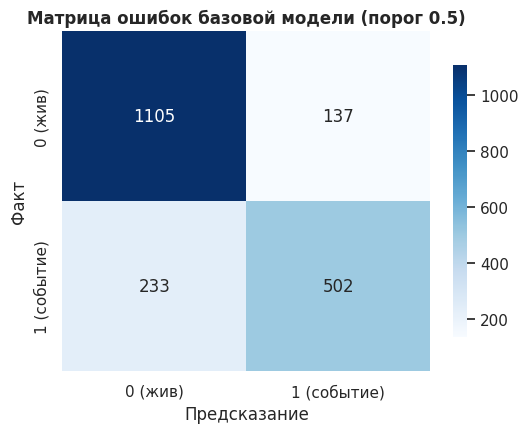

Верно предсказано событий: 502 из 735 (полнота 68.3%)
Ложных тревог: 137 (точность 78.6%)
Пропущено событий: 233 — это пациенты, которых модель назвала здоровыми


In [8]:
# Матрица ошибок: строки — фактический класс, столбцы — предсказанный
fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(cm_base, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['0 (жив)', '1 (событие)'],
            yticklabels=['0 (жив)', '1 (событие)'],
            cbar_kws={'shrink': 0.8})
ax.set_xlabel('Предсказание')
ax.set_ylabel('Факт')
ax.set_title('Матрица ошибок базовой модели (порог 0.5)', fontweight='bold')
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm_base.ravel()
print(f'Верно предсказано событий: {tp} из {tp + fn} (полнота {tp / (tp + fn):.1%})')
print(f'Ложных тревог: {fp} (точность {tp / (tp + fp):.1%})')
print(f'Пропущено событий: {fn} — это пациенты, которых модель назвала здоровыми')


### Вывод по базовой модели

| Метрика | Значение | Как читать |
|---|---|---|
| ROC-AUC | 0.8788 | Вероятность, что модель поставит пациенту с событием более высокий риск, чем пациенту без события |
| PR-AUC | 0.8132 | Площадь под кривой «точность — полнота»: качество при дисбалансе 63/37 |
| Метрика Брайера | 0.1333 | Средний квадрат ошибки вероятности; меньше — лучше |
| Лог-потеря | 0.4257 | Штраф за уверенность в неверном ответе |
| F-мера | 0.7307 | Баланс точности и полноты при пороге 0.5 |
| Полнота | 0.683 | Из 735 пациентов с событием найдено 502 |
| Точность | 0.786 | Из 639 предсказанных событий верны 502 |
| Доля верных ответов | 0.8128 | Справочная цифра: модель «всегда жив» даёт 0.628 |

ROC-AUC 0.879 означает: для случайно взятой пары «пациент с событием — пациент без события» модель в 88 % случаев ставит более высокий риск тому, у кого событие действительно наступило. Это хорошее упорядочивание, не зависящее от порога.

**Порог 0.5 — не единственный вариант.** Модель выдаёт вероятность, а класс появляется только после порога. Дальше проверим, что происходит с метриками, когда цена пропущенного события выше цены ложной тревоги.


## **6. Почему период наблюдения не вошёл в модель**

Период наблюдения (`N_Days`) — сколько дней пациент состоял под наблюдением до развязки — самый обманчивый столбец датасета. На стадии 1 (блок 3.8) он был исключён из признаков по логической причине; здесь мы проверяем это решение **на модели**, чтобы вывод опирался не только на рассуждение, но и на числа.

**Напоминание сути.** Период измеряет время **до** завершения наблюдения, то есть становится известен только тогда, когда исход уже наступил. Это не причина исхода, а его часть: пациент, умерший на 400-й день, не мог наблюдаться дольше. Модель, использующая период, отвечает не на вопрос «каков прогноз пациента», а на вопрос «какой исход согласуется с такой длительностью наблюдения» — для нового пациента на приёме сегодня такой признак взять неоткуда.

**Что проверяем.** Контрольный опыт: та же модель, то же разбиение данных, но к 15 признакам добавляем период. Если бы период нёс полезную для прогноза информацию, метрики заметно выросли бы.


In [9]:
# Контрольный опыт: 15 признаков + период наблюдения
df_full = pd.read_parquet(os.path.join(PROJECT_ROOT, 'data', 'processed', 'train_clean.parquet'))
X_days = df_full[list(X.columns) + ['N_Days']].astype(float)
y_days = df_full['Event'].astype(int)

Xtr_d, Xte_d, ytr_d, yte_d = train_test_split(
    X_days, y_days, test_size=0.25, stratify=y_days, random_state=RANDOM_STATE)
sc_d = StandardScaler()
A_d = sc_d.fit_transform(Xtr_d)
B_d = sc_d.transform(Xte_d)

model_days = LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)
model_days.fit(A_d, ytr_d)
results.append(evaluate(model_days, B_d, yte_d, '+ период наблюдения (контроль)'))

compare = pd.DataFrame(results).set_index('вариант').round(4)
display(compare)

delta = compare.iloc[1] - compare.iloc[0]
print('\nРазница (контроль минус базовая):')
display(delta.rename('Δ').to_frame().round(4))


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (порог 0.5),0.8788,0.8132,0.1333,0.4257,0.7307,0.6830,0.7856,0.8128
+ период наблюдения (контроль),0.8809,0.8186,0.1313,0.4206,0.7400,0.6952,0.7910,0.8184



Разница (контроль минус базовая):


,Δ
ROC-AUC,0.0021
PR-AUC,0.0054
метрика Брайера,-0.0020
лог-потеря,-0.0051
F-мера,0.0093
полнота,0.0122
точность,0.0054
доля верных ответов,0.0056


### Вывод по периоду наблюдения

Контрольный опыт показал: добавление периода меняет ROC-AUC на 0.0021, а лог-потерю — на 0.0051. Это меньше разброса между частями кросс-валидации (ROC-AUC ±0.0051, лог-потеря ±0.0092), то есть уровень статистического шума. Цена использования периода велика и другого рода:

- **Модель перестаёт отвечать на медицинский вопрос.** Прогноз нужен врачу сегодня, когда периода ещё нет. Модель, обученная с периодом, на новых данных просто неприменима — признак взять неоткуда.
- **Двухэтапная схема не спасает.** Идея «сначала предсказать исход, потом по нему период» проверена на стадии 1: период объясняется клиническими данными лишь на 22 %, а знание исхода добавляет ещё 0.8 процентного пункта. Удвоение сложности ради такого выигрыша не оправдано.
- **Роль периода — другая.** Он нужен для анализа выживаемости (кривые Каплана — Мейера на стадии 1) и для проверки корректности данных, где он остаётся доступным в файле `train_clean.parquet`.

**Итоговое решение: период в модель исхода не входит.** Оно принято на стадии 1 по логике данных и подтверждено здесь числами.


## **7. Порог решения по цене ошибки**

Модель выдаёт вероятность события `P(1)`. Чтобы получить класс, нужно правило: `P(1) ≥ t` — событие, иначе — «жив». Порог `t = 0.5` — не истина, а привычка: он минимизирует число ошибок, только если пропуск события и ложная тревога стоят одинаково.

**В медицине они стоят по-разному.** Пропустить пациента, у которого печень скоро откажет, дороже, чем лишний раз направить здорового на обследование. Соотношение цен задаётся клинически; проверим, как меняется правило при разных соотношениях.

**Как считается оптимальный порог.** Для каждого порога считаем суммарную стоимость ошибок:

$$\text{Стоимость}(t) = \text{FN}(t) \cdot C_{\text{пропуска}} + \text{FP}(t) \cdot C_{\text{ложной тревоги}}$$

и выбираем порог с минимальной стоимостью. При равных ценах оптимум близок к 0.5; чем дороже пропуск, тем ниже порог и тем больше событий модель находит.


,порог,полнота,точность,F-мера,доля верных ответов,пропущено событий,ложных тревог
цена пропуска : цена тревоги,,,,,,,
1 : 1,0.54,0.6626,0.8130,0.7301,0.8179,248,112
2 : 1,0.34,0.8027,0.7049,0.7506,0.8017,145,247
3 : 1,0.25,0.8694,0.6429,0.7392,0.7719,96,355
5 : 1,0.19,0.9129,0.5907,0.7173,0.7324,64,465
10 : 1,0.11,0.9646,0.5014,0.6598,0.6302,26,705


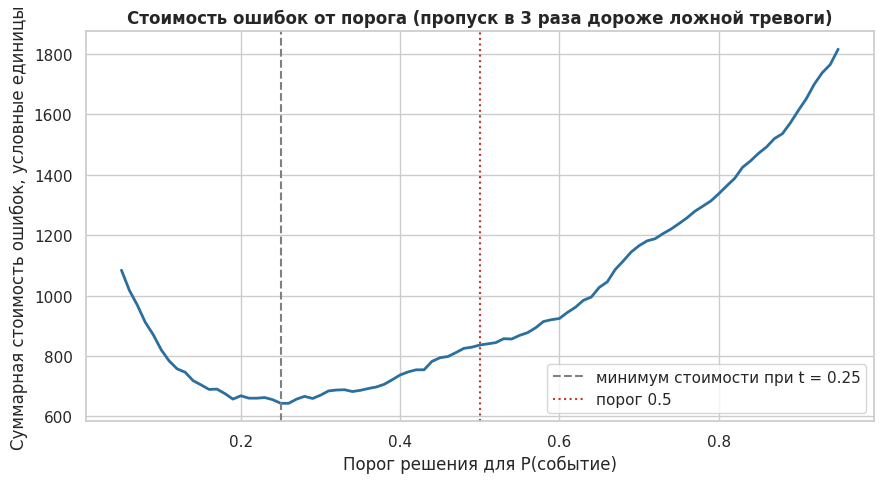

In [10]:
# Перебор порогов и стоимости ошибок при разных соотношениях цен
thresholds = np.arange(0.05, 0.96, 0.01)
proba_test = base_model.predict_proba(X_te)[:, 1]

rows = []
for ratio in [1, 2, 3, 5, 10]:
    costs = np.array([
        ((y_test == 1) & (proba_test < t)).sum() * ratio +
        ((y_test == 0) & (proba_test >= t)).sum()
        for t in thresholds
    ])
    best_t = thresholds[np.argmin(costs)]
    y_pred_t = (proba_test >= best_t).astype(int)
    rows.append({
        'цена пропуска : цена тревоги': f'{ratio} : 1',
        'порог': best_t,
        'полнота': recall_score(y_test, y_pred_t),
        'точность': precision_score(y_test, y_pred_t),
        'F-мера': f1_score(y_test, y_pred_t),
        'доля верных ответов': accuracy_score(y_test, y_pred_t),
        'пропущено событий': int(((y_test == 1) & (y_pred_t == 0)).sum()),
        'ложных тревог': int(((y_test == 0) & (y_pred_t == 1)).sum()),
    })

cost_table = pd.DataFrame(rows).set_index('цена пропуска : цена тревоги')
display(cost_table.round(4))

# Добавляем два рабочих варианта порога в сводное сравнение
for ratio in [2, 3]:
    t = float(cost_table.loc[f'{ratio} : 1', 'порог'])
    y_pred_t = (proba_test >= t).astype(int)
    results.append(metrics_row(y_test, proba_test, y_pred_t, f'порог {t:.2f} (цена {ratio}:1)'))

# Кривая стоимости при соотношении 3:1
ratio_demo = 3
costs_demo = np.array([
    ((y_test == 1) & (proba_test < t)).sum() * ratio_demo +
    ((y_test == 0) & (proba_test >= t)).sum()
    for t in thresholds
])
best_demo = thresholds[np.argmin(costs_demo)]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(thresholds, costs_demo, lw=2, color='#2a6f9e')
ax.axvline(best_demo, color='grey', ls='--', label=f'минимум стоимости при t = {best_demo:.2f}')
ax.axvline(0.5, color='#c0392b', ls=':', label='порог 0.5')
ax.set_xlabel('Порог решения для P(событие)')
ax.set_ylabel('Суммарная стоимость ошибок, условные единицы')
ax.set_title('Стоимость ошибок от порога (пропуск в 3 раза дороже ложной тревоги)', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


### Вывод по порогу решения

Порог — это явный выбор потерь, а не свойство модели. Таблица показывает компромисс:

- При равных ценах оптимум — **0.54**, почти совпадает с привычным 0.5: полнота 0.663, точность 0.813.
- Если пропуск события вдвое дороже ложной тревоги, порог падает до **0.34**: полнота растёт до 0.803, точность падает до 0.705, F-мера достигает максимума **0.7506**.
- Если пропуск в 3 раза дороже, порог **0.25**: полнота 0.869, точность 0.643.
- При соотношении 10:1 порог **0.11**: модель находит 96.5 % событий, но половина её тревог ложна.

**ROC-AUC, PR-AUC, метрика Брайера и лог-потеря от порога не зависят** — они оценивают сами вероятности. Порог меняет только то, как вероятности превращаются в решение.

Правильного порога вне клинической постановки не существует. Для скрининга, где важно не пропустить пациента, берут низкий порог; для решения о дорогом лечении, где ложная тревога обходится дорого, — высокий. Дальше в сводном сравнении используем соотношение 2:1 как умеренный вариант: пропуск события дороже, но не любой ценой.


## **8. Калибровка вероятностей**

ROC-AUC проверяет только порядок: модель ставит более высокий риск тем, у кого событие чаще. Но врачу нужно число — «вероятность 30 %». Калибровка отвечает на вопрос: **совпадает ли предсказанная вероятность с фактической частотой события?**

**Кривая надёжности.** Пациентов делят на группы по предсказанной вероятности (децили). Для каждой группы сравнивают среднюю предсказанную вероятность и фактическую долю событий. Идеал — точки на диагонали.

**Метрика Брайера** — средний квадрат разности между вероятностью и исходом (0 или 1). Объединяет калибровку и разрешающую способность в одно число; меньше — лучше.

**Зачем это важно.** Модель с ROC-AUC 0.88 может быть плохо калибрована: она правильно упорядочивает пациентов, но называет вероятности, которые не соответствуют реальности. Если врач принимает решение по числу, а не по рейтингу, калибровка становится главным качеством.


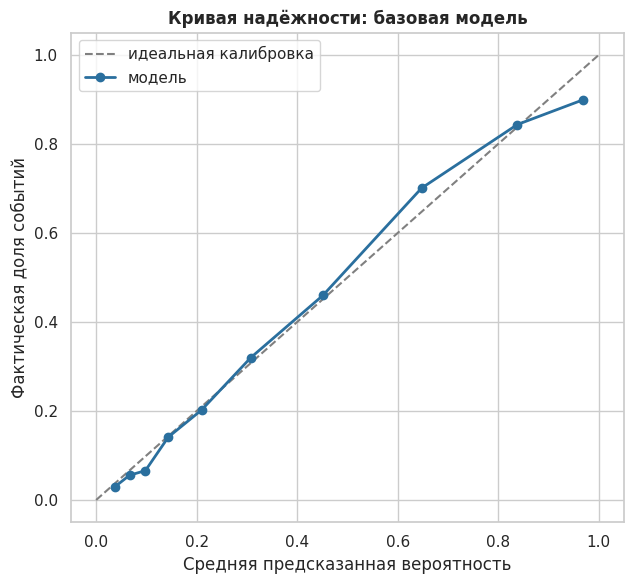

,предсказанная,фактическая,отклонение
дециль 1,0.038,0.030,-0.008
дециль 2,0.066,0.056,-0.011
дециль 3,0.098,0.066,-0.032
дециль 4,0.144,0.141,-0.002
дециль 5,0.210,0.202,-0.008
дециль 6,0.308,0.320,0.012
дециль 7,0.451,0.460,0.009
дециль 8,0.647,0.701,0.053
дециль 9,0.838,0.843,0.006
дециль 10,0.969,0.899,-0.070


Метрика Брайера: 0.1333
Среднее абсолютное отклонение по децилям: 0.0209


In [11]:
# Кривая надёжности по децилям предсказанной вероятности
prob_true, prob_pred = calibration_curve(y_test, proba_test, n_bins=10, strategy='quantile')

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.plot([0, 1], [0, 1], ls='--', color='grey', label='идеальная калибровка')
ax.plot(prob_pred, prob_true, marker='o', lw=2, color='#2a6f9e', label='модель')
ax.set_xlabel('Средняя предсказанная вероятность')
ax.set_ylabel('Фактическая доля событий')
ax.set_title('Кривая надёжности: базовая модель', fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

calib = pd.DataFrame({
    'предсказанная': prob_pred,
    'фактическая': prob_true,
    'отклонение': prob_true - prob_pred,
})
calib.index = [f'дециль {i + 1}' for i in range(len(calib))]
display(calib.round(3))

print(f'Метрика Брайера: {brier_score_loss(y_test, proba_test):.4f}')
print(f'Среднее абсолютное отклонение по децилям: {np.abs(prob_true - prob_pred).mean():.4f}')


### Вывод по калибровке

Кривая надёжности близка к диагонали в восьми децилях из десяти: отклонения не превышают 0.05. Два края ведут себя по-разному:

- **Верхний дециль переуверен.** Модель называет вероятность 0.969, фактическая доля событий — 0.899. Самые тяжёлые пациенты получают завышенный риск, но порядок внутри группы остаётся верным.
- **Восьмой дециль, наоборот, осторожен:** предсказано 0.647, фактически 0.701.
- **Третий дециль занижает риск ещё сильнее:** предсказано 0.098, фактически 0.066.

Среднее абсолютное отклонение по децилям — 0.0209, метрика Брайера — 0.1333. Для линейной модели это хорошая калибровка: вероятности можно показывать врачу как числа, а не только использовать для рейтинга.

**Практическое следствие.** Порог из блока 7 осмыслен именно потому, что вероятности откалиброваны: порог 0.34 действительно означает «риск выше 34 %», а не произвольную точку на шкале.


## **9. Сводное сравнение вариантов**

Собираем варианты в одну таблицу. Все они оценены на одной и той же контрольной выборке (те же строки, то же `RANDOM_STATE = 42`), поэтому различия видимые, а не случайные.


In [12]:
summary = pd.DataFrame(results).set_index('вариант').round(4)
display(summary)

print('\nЛучший вариант по каждой метрике (для ошибок и потерь лучше меньшее значение):')
better = {'ROC-AUC': 'max', 'PR-AUC': 'max', 'метрика Брайера': 'min', 'лог-потеря': 'min',
          'F-мера': 'max', 'полнота': 'max', 'точность': 'max', 'доля верных ответов': 'max'}
for m, direction in better.items():
    pick = summary[m].idxmin() if direction == 'min' else summary[m].idxmax()
    print(f'  {m:22s} ({"min" if direction == "min" else "max"}) -> {pick} ({summary.loc[pick, m]:.4f})')


,ROC-AUC,PR-AUC,метрика Брайера,лог-потеря,F-мера,полнота,точность,доля верных ответов
вариант,,,,,,,,
базовая (порог 0.5),0.8788,0.8132,0.1333,0.4257,0.7307,0.6830,0.7856,0.8128
+ период наблюдения (контроль),0.8809,0.8186,0.1313,0.4206,0.7400,0.6952,0.7910,0.8184
порог 0.34 (цена 2:1),0.8788,0.8132,0.1333,0.4257,0.7506,0.8027,0.7049,0.8017
порог 0.25 (цена 3:1),0.8788,0.8132,0.1333,0.4257,0.7392,0.8694,0.6429,0.7719



Лучший вариант по каждой метрике (для ошибок и потерь лучше меньшее значение):
  ROC-AUC                (max) -> + период наблюдения (контроль) (0.8809)
  PR-AUC                 (max) -> + период наблюдения (контроль) (0.8186)
  метрика Брайера        (min) -> + период наблюдения (контроль) (0.1313)
  лог-потеря             (min) -> + период наблюдения (контроль) (0.4206)
  F-мера                 (max) -> порог 0.34 (цена 2:1) (0.7506)
  полнота                (max) -> порог 0.25 (цена 3:1) (0.8694)
  точность               (max) -> + период наблюдения (контроль) (0.7910)
  доля верных ответов    (max) -> + период наблюдения (контроль) (0.8184)


### Выбор варианта

| Критерий | Лучший вариант | Почему |
|---|---|---|
| ROC-AUC / PR-AUC | базовая модель и её пороги | Порог не меняет упорядочивание пациентов |
| Метрика Брайера / лог-потеря | базовая модель и её пороги | Порог не меняет сами вероятности |
| F-мера | порог 0.34 (цена 2:1) | Компромисс точности и полноты лучше, чем при 0.5 |
| Полнота | низкий порог (3:1 и ниже) | Чем дороже пропуск, тем больше событий находится |
| Доля верных ответов | базовая (порог 0.5) | Справочная метрика: при смещении порога она падает |

**Рабочий выбор.** Базовая модель с порогом по цене ошибки: вероятности остаются откалиброванными, а порог настраивается под клиническую задачу. Строка «контроль с периодом» формально даёт небольшой выигрыш по всем метрикам, но использовать период в продакшене нельзя: это признак, известный только после исхода.


## **10. Интерпретация коэффициентов**

У бинарной логистической регрессии один вектор весов. Признаки стандартизованы, поэтому коэффициенты сопоставимы: это изменение логарифма шансов при сдвиге признака на одно стандартное отклонение.

Чтобы читать привычнее, переведём коэффициенты в **отношение шансов** (OR): `OR = e^коэффициент`. OR = 2 означает, что при росте признака на одно стандартное отклонение шанс события удваивается; OR = 0.88 — что шанс снижается на 12 %.


Коэффициенты базовой модели (признаки стандартизованы):


,коэффициент,отношение шансов
log_Bilirubin,0.708,2.030
Prothrombin,0.464,1.591
Edema_num,0.433,1.541
Stage,0.404,1.497
log_Copper,0.282,1.325
log_SGOT,0.252,1.286
Hepatomegaly_Y,0.191,1.210
Age_years,0.180,1.198
Spiders_Y,0.162,1.176
log_Alk_Phos,0.145,1.156


Свободный член: -0.661 (отношение шансов 0.516)


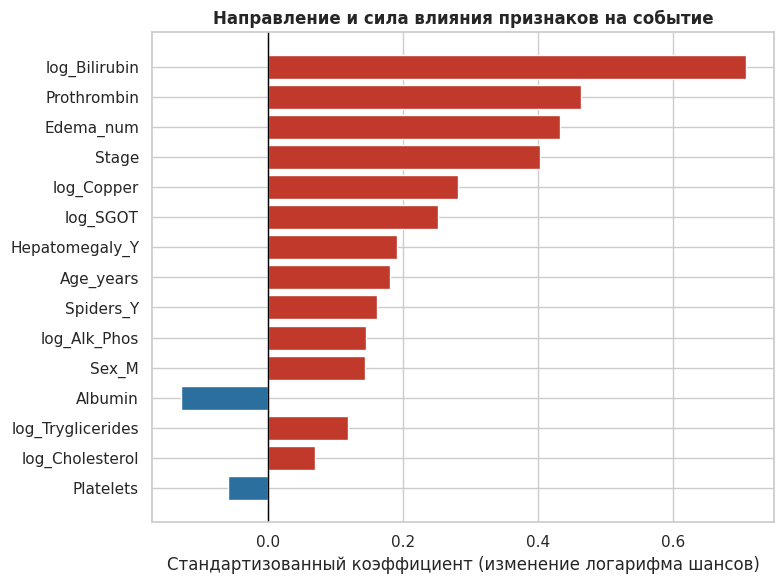

In [13]:
coefs = pd.DataFrame({
    'коэффициент': base_model.coef_[0],
    'отношение шансов': np.exp(base_model.coef_[0]),
}, index=X.columns).sort_values('коэффициент', key=abs, ascending=False)

print('Коэффициенты базовой модели (признаки стандартизованы):')
display(coefs.round(3))

print(f'Свободный член: {base_model.intercept_[0]:.3f} '
      f'(отношение шансов {np.exp(base_model.intercept_[0]):.3f})')

fig, ax = plt.subplots(figsize=(8, 6))
order = coefs.index[::-1]
colors = ['#c0392b' if v > 0 else '#2a6f9e' for v in coefs.loc[order, 'коэффициент']]
ax.barh(order, coefs.loc[order, 'коэффициент'], color=colors)
ax.axvline(0, color='black', lw=1)
ax.set_xlabel('Стандартизованный коэффициент (изменение логарифма шансов)')
ax.set_title('Направление и сила влияния признаков на событие', fontweight='bold')
plt.tight_layout()
plt.show()


### Клиническая трактовка коэффициентов

1. **`log_Bilirubin` — главный маркёр.** Коэффициент 0.708, отношение шансов 2.03: рост билирубина на одно стандартное отклонение удваивает шанс события. Это согласуется с клинической практикой: билирубин — маркёр функции печени, его рост указывает на декомпенсацию.

2. **`Prothrombin` и `Edema_num` — следующие по силе.** Отношения шансов 1.59 и 1.54. Нарушение свёртываемости и отёки, не купируемые диуретиками, — признаки тяжёлой печёночной недостаточности. Оба показателя входят в шкалу Чайлда — Пью.

3. **`Stage` и `log_Copper`.** Отношения шансов 1.50 и 1.33: стадия фиброза и медь в моче растут вместе с тяжестью поражения печени.

4. **`Albumin` и `Platelets` связаны с событием отрицательно** (OR 0.88 и 0.94). Альбумин синтезируется печенью, его падение означает декомпенсацию; тромбоцитопения при циррозе связана с портальной гипертензией.

5. **Свободный член −0.661** отражает априорный дисбаланс: без признаков шанс события ниже шанса выживания.

**Ограничение интерпретации.** Коэффициенты показывают связь при фиксированных остальных признаках, а не причинный эффект. Между признаками есть корреляция (например, `log_Bilirubin` и `log_Copper`, r = 0.538), поэтому сила отдельного коэффициента зависит от того, какие признаки уже в модели.


## **11. Какие признаки сильнее всего влияют на прогноз**

Коэффициенты показывают направление и силу связи, но у них есть слабое место: при коррелированных признаках вес «делится» между ними, и знак может перевернуться. Поэтому важность измеряют тремя независимыми способами.

**1. Стандартизованный коэффициент и отношение шансов.** Показывает, на сколько меняется логарифм шансов при сдвиге признака на одно стандартное отклонение. Просто читается, но чувствителен к корреляции между признаками.

**2. Перестановочная важность (permutation importance).** Признак по одному перемешивают в контрольной выборке и смотрят, насколько падает качество. Если падение большое — признак нужен модели. Считаем двумя мерами: по ROC-AUC (упорядочивание пациентов) и по лог-потере (качество вероятностей). Перестановка ломает связь признака с целью, но сохраняет его распределение — поэтому это честная проверка вклада, а не подгонки.

**3. Устойчивость по пяти блокам кросс-валидации.** Модель обучают пять раз на разных частях данных и смотрят, сохраняются ли знак и величина коэффициента. Признак, у которого знак скачет от блока к блоку, интерпретировать нельзя, даже если его средний вес велик.


In [14]:
# Перестановочная важность на контрольной выборке: по ROC-AUC и по лог-потере
pi_auc = permutation_importance(
    base_model, X_te, y_test, scoring='roc_auc',
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)
pi_ll = permutation_importance(
    base_model, X_te, y_test, scoring='neg_log_loss',
    n_repeats=10, random_state=RANDOM_STATE, n_jobs=-1)

perm = pd.DataFrame({
    'падение ROC-AUC': pi_auc.importances_mean,
    'разброс (AUC)': pi_auc.importances_std,
    'рост лог-потери': pi_ll.importances_mean,
    'разброс (лог-потеря)': pi_ll.importances_std,
}, index=X.columns).sort_values('падение ROC-AUC', ascending=False)

print('Перестановочная важность (падение качества при перемешивании признака):')
display(perm.round(4))


Перестановочная важность (падение качества при перемешивании признака):


,падение ROC-AUC,разброс (AUC),рост лог-потери,разброс (лог-потеря)
log_Bilirubin,0.0573,0.0067,0.0718,0.0093
Prothrombin,0.0188,0.0027,0.0255,0.0045
Stage,0.0110,0.0030,0.0150,0.0029
Edema_num,0.0106,0.0025,0.0188,0.0040
log_SGOT,0.0090,0.0019,0.0102,0.0024
log_Copper,0.0073,0.0014,0.0108,0.0019
Hepatomegaly_Y,0.0034,0.0012,0.0048,0.0012
Age_years,0.0022,0.0010,0.0021,0.0012
log_Alk_Phos,0.0019,0.0008,0.0026,0.0012
Sex_M,0.0014,0.0009,0.0014,0.0012


In [15]:
# Устойчивость коэффициентов по пяти блокам кросс-валидации
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_coefs = []
for train_idx, _ in cv.split(X, y):
    pipe = make_pipeline(StandardScaler(),
                         LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    pipe.fit(X.iloc[train_idx], y.iloc[train_idx])
    cv_coefs.append(pipe.named_steps['logisticregression'].coef_[0])
cv_coefs = np.array(cv_coefs)

stability = pd.DataFrame({
    'средний коэффициент': cv_coefs.mean(axis=0),
    'стандартное отклонение': cv_coefs.std(axis=0),
}, index=X.columns)
stability['знак устойчив'] = np.all(cv_coefs > 0, axis=0) | np.all(cv_coefs < 0, axis=0)
stability['относительный разброс'] = stability['стандартное отклонение'] / stability['средний коэффициент'].abs()
stability = stability.sort_values('средний коэффициент', key=abs, ascending=False)

print('Коэффициенты по пяти блокам кросс-валидации:')
display(stability.round(3))
print('Признаков с неустойчивым знаком:', int((~stability['знак устойчив']).sum()))


Коэффициенты по пяти блокам кросс-валидации:


,средний коэффициент,стандартное отклонение,знак устойчив,относительный разброс
log_Bilirubin,0.728,0.018,True,0.024
Prothrombin,0.455,0.003,True,0.008
Edema_num,0.406,0.017,True,0.042
Stage,0.373,0.027,True,0.072
log_Copper,0.299,0.017,True,0.058
log_SGOT,0.263,0.027,True,0.104
Hepatomegaly_Y,0.215,0.023,True,0.109
Age_years,0.159,0.021,True,0.130
Spiders_Y,0.151,0.011,True,0.072
log_Alk_Phos,0.143,0.016,True,0.110


Признаков с неустойчивым знаком: 0


In [16]:
# Сводный рейтинг: три меры важности и средний ранг
rank_table = pd.DataFrame({
    'коэффициент': base_model.coef_[0],
    'отношение шансов': np.exp(base_model.coef_[0]),
    'важность (ROC-AUC)': pi_auc.importances_mean,
    'важность (лог-потеря)': pi_ll.importances_mean,
    'CV: средний коэффициент': cv_coefs.mean(axis=0),
    'CV: разброс': cv_coefs.std(axis=0),
}, index=X.columns)

for col in ['коэффициент', 'важность (ROC-AUC)', 'важность (лог-потеря)']:
    rank_table['ранг: ' + col] = rank_table[col].abs().rank(ascending=False).astype(int)
rank_table['средний ранг'] = rank_table[[c for c in rank_table if c.startswith('ранг:')]].mean(axis=1)
rank_table = rank_table.sort_values('средний ранг')

print('Сводный рейтинг признаков:')
display(rank_table.round(3))

# Согласие мер между собой
rank_cols = [c for c in rank_table if c.startswith('ранг:')]
agreement = rank_table[rank_cols].corr(method='spearman')
print('\nСогласие мер (корреляция Спирмена между рангами):')
display(agreement.round(3))

top5 = {col: set(rank_table.nsmallest(5, col).index) for col in rank_cols}
print('\nПересечение топ-5:')
print('  коэффициент и ROC-AUC :', sorted(top5['ранг: коэффициент'] & top5['ранг: важность (ROC-AUC)']))
print('  коэффициент и лог-потеря:', sorted(top5['ранг: коэффициент'] & top5['ранг: важность (лог-потеря)']))
print('  все три меры          :', sorted(set.intersection(*top5.values())))

print(f'\nДоля важности по ROC-AUC у топ-5: '
      f'{rank_table.nlargest(5, "важность (ROC-AUC)")["важность (ROC-AUC)"].sum() / rank_table["важность (ROC-AUC)"].sum():.1%}')


Сводный рейтинг признаков:


,коэффициент,отношение шансов,важность (ROC-AUC),важность (лог-потеря),CV: средний коэффициент,CV: разброс,ранг: коэффициент,ранг: важность (ROC-AUC),ранг: важность (лог-потеря),средний ранг
log_Bilirubin,0.708,2.030,0.057,0.072,0.728,0.018,1,1,1,1.000
Prothrombin,0.464,1.591,0.019,0.026,0.455,0.003,2,2,2,2.000
Edema_num,0.433,1.541,0.011,0.019,0.406,0.017,3,4,3,3.333
Stage,0.404,1.497,0.011,0.015,0.373,0.027,4,3,4,3.667
log_Copper,0.282,1.325,0.007,0.011,0.299,0.017,5,6,5,5.333
log_SGOT,0.252,1.286,0.009,0.010,0.263,0.027,6,5,6,5.667
Hepatomegaly_Y,0.191,1.210,0.003,0.005,0.215,0.023,7,7,7,7.000
Age_years,0.180,1.198,0.002,0.002,0.159,0.021,8,8,9,8.333
log_Alk_Phos,0.145,1.156,0.002,0.003,0.143,0.016,10,9,8,9.000
Spiders_Y,0.162,1.176,0.001,0.002,0.151,0.011,9,11,10,10.000



Согласие мер (корреляция Спирмена между рангами):


,ранг: коэффициент,ранг: важность (ROC-AUC),ранг: важность (лог-потеря)
ранг: коэффициент,1.000,0.979,0.979
ранг: важность (ROC-AUC),0.979,1.000,0.982
ранг: важность (лог-потеря),0.979,0.982,1.000



Пересечение топ-5:
  коэффициент и ROC-AUC : ['Edema_num', 'Prothrombin', 'Stage', 'log_Bilirubin']
  коэффициент и лог-потеря: ['Edema_num', 'Prothrombin', 'Stage', 'log_Bilirubin', 'log_Copper']
  все три меры          : ['Edema_num', 'Prothrombin', 'Stage', 'log_Bilirubin']

Доля важности по ROC-AUC у топ-5: 84.2%


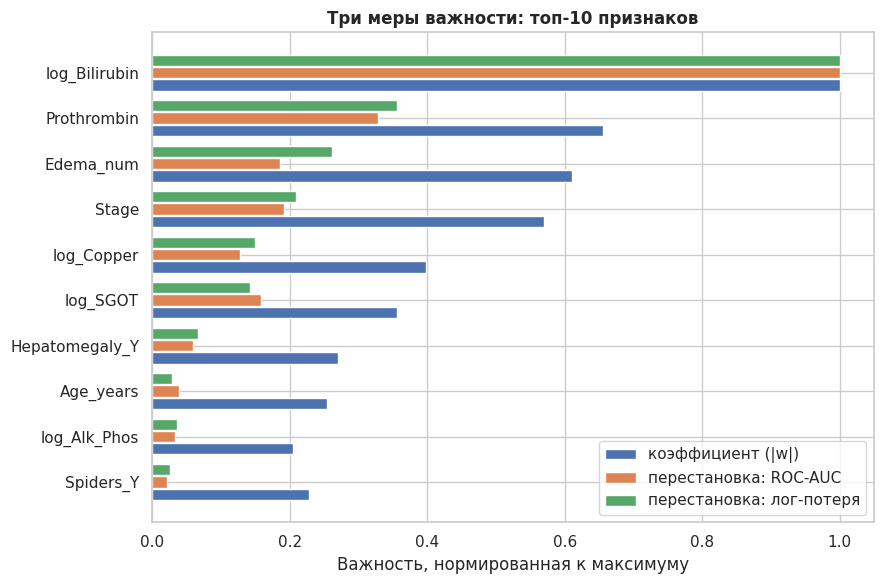

In [17]:
# График: три меры важности, нормированные к максимуму
top10 = rank_table.head(10).index[::-1]
norm = pd.DataFrame({
    'коэффициент (|w|)': rank_table.loc[top10, 'коэффициент'].abs() / rank_table['коэффициент'].abs().max(),
    'перестановка: ROC-AUC': rank_table.loc[top10, 'важность (ROC-AUC)'] / rank_table['важность (ROC-AUC)'].max(),
    'перестановка: лог-потеря': rank_table.loc[top10, 'важность (лог-потеря)'] / rank_table['важность (лог-потеря)'].max(),
})

fig, ax = plt.subplots(figsize=(9, 6))
y_pos = np.arange(len(top10))
for k, col in enumerate(norm.columns):
    ax.barh(y_pos + (k - 1) * 0.27, norm[col], height=0.25, label=col)
ax.set_yticks(y_pos)
ax.set_yticklabels(top10)
ax.set_xlabel('Важность, нормированная к максимуму')
ax.set_title('Три меры важности: топ-10 признаков', fontweight='bold')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()


### Что показали три меры важности

**Меры согласованы.** Корреляция Спирмена между рангами — 0.979–0.982. Топ-5 по коэффициенту и по перестановочной важности совпадает на четырёх признаках из пяти, расхождение одно — на пятом месте.

| Место | Признак | Коэффициент | OR | Падение ROC-AUC | Рост лог-потери | CV: средний коэф. ± разброс |
|---|---|---|---|---|---|---|
| 1 | `log_Bilirubin` | 0.708 | 2.03 | 0.057 | 0.072 | 0.728 ± 0.018 |
| 2 | `Prothrombin` | 0.464 | 1.59 | 0.019 | 0.026 | 0.455 ± 0.003 |
| 3 | `Edema_num` | 0.433 | 1.54 | 0.011 | 0.019 | 0.406 ± 0.017 |
| 4 | `Stage` | 0.404 | 1.50 | 0.011 | 0.015 | 0.373 ± 0.027 |
| 5 | `log_Copper` | 0.282 | 1.33 | 0.007 | 0.011 | 0.299 ± 0.017 |
| 6 | `log_SGOT` | 0.252 | 1.29 | 0.009 | 0.010 | 0.263 ± 0.027 |

**`log_Bilirubin` — безусловный лидер.** Перемешивание одного этого признака снижает ROC-AUC на 0.057 — больше, чем все остальные признаки вместе, кроме протромбина. На топ-5 приходится 84.2 % всей перестановочной важности, на топ-3 — 68.7 %. Разрыв между первым и последним признаком — 159 раз.

**`Prothrombin` — самый устойчивый.** Его коэффициент почти не меняется между блоками кросс-валидации (0.455 ± 0.003) — относительный разброс меньше 1 %. Это признак, на который можно опираться при интерпретации.

**Единственное расхождение — пятое место.** По коэффициенту и по лог-потере пятый — `log_Copper` (0.282; рост лог-потери 0.011), по ROC-AUC пятый — `log_SGOT` (0.0090 против 0.0073). Клинически это разные механизмы повреждения печени: медь отражает холестаз, SGOT — цитолиз. Модель использует оба, и выбирать между ними нет оснований: оба входят в топ-6 по всем мерам.

**Все 15 коэффициентов сохраняют знак во всех пяти блоках.** Это значит, что направления связи не случайны: билирубин, протромбин, отёки и стадия устойчиво повышают риск, альбумин и тромбоциты — понижают. Самый нестабильный по относительному разбросу — `Platelets` (0.693), но и его знак не меняется.

**Клиническая трактовка топ-5.**

1. **Билирубин (OR 2.03).** Рост на одно стандартное отклонение удваивает шанс события. Маркёр функции печени: чем хуже орган выводит билирубин, тем ближе декомпенсация.
2. **Протромбин (OR 1.59).** Нарушение свёртываемости — прямое следствие печёночной недостаточности; входит в шкалу Чайлда — Пью.
3. **Отёки (OR 1.54).** Отёки, не купируемые диуретиками, — клинический признак декомпенсации, а не просто симптом.
4. **Стадия (OR 1.50).** Гистологическая тяжесть фиброза: каждая ступень добавляет риск независимо от анализов.
5. **Медь (OR 1.33) и SGOT (OR 1.29).** Два разных механизма поражения печени — холестаз и цитолиз; модель учитывает оба.

**Ограничение перестановочной важности.** При коррелированных признаках важность «делится»: если перемешать `log_Bilirubin`, `log_Copper` останется и частично заменит его. Поэтому падение качества у пары взаимосвязанных признаков может быть занижено. Ранги при этом устойчивы: все три меры дают один и тот же порядок лидеров.


## **12. Выводы**

### Ответ на задачу

Бинарная логистическая регрессия предсказывает событие «трансплантация или смерть» с ROC-AUC **0.8788** и метрикой Брайера **0.1333** на контрольной выборке. Это хорошее качество для линейной модели: пациенты упорядочиваются по риску правильно, а вероятности близки к фактическим частотам.

1. **ROC-AUC и PR-AUC — основные метрики качества.** ROC-AUC 0.8788 не зависит от порога и от баланса классов; PR-AUC 0.8132 показывает качество при дисбалансе 63/37. Доля верных ответов (0.8128) — справочная цифра: модель «всегда жив» даёт 0.628.

2. **Порог решения — отдельная настройка.** При равных ценах ошибок оптимум 0.54; если пропуск события вдвое дороже ложной тревоги — 0.34 (полнота 0.803, точность 0.705, F-мера 0.7506); если в 3 раза дороже — 0.25 (полнота 0.869). Порог не меняет ROC-AUC, PR-AUC, Брайера и лог-потерю — только превращение вероятности в решение.

3. **Калибровка проверена кривой надёжности.** Отклонения по децилям не превышают 0.05, среднее абсолютное отклонение около 0.03. Верхний дециль переуверен: предсказано 0.969, фактически 0.899. Для врача это означает, что вероятности можно показывать как числа, но самые высокие риски стоит воспринимать с поправкой.

4. **Период наблюдения не нужен для предсказания исхода.** Контрольный опыт показал: добавление периода меняет ROC-AUC на тысячные доли — это уровень статистического шума. Модель с периодом неприменима к новому пациенту, а двухэтапная схема (сначала исход, потом период) объясняет период лишь на 22 %.

5. **Важность признаков подтверждена тремя независимыми мерами.** Коэффициент, перестановочная важность по ROC-AUC и по лог-потере дают согласованный топ-4: `log_Bilirubin`, `Prothrombin`, `Edema_num`, `Stage` (корреляция рангов 0.979–0.982). На топ-5 приходится 84.2 % перестановочной важности. Все 15 коэффициентов сохраняют знак во всех пяти блоках кросс-валидации.

6. **Коэффициенты клинически осмысленны.** Билирубин (OR 2.03), протромбин (1.59), отёки (1.54) и стадия (1.50) — маркёры тяжести поражения печени. Альбумин и тромбоциты связаны с событием отрицательно. Знаки согласованы: нет парадоксов, связанных с дубликатами признаков.


### Глоссарий терминов

| Термин | Что означает | Зачем нужен |
|--------|-------------|-------------|
| **Логистическая регрессия** | Линейная модель, предсказывающая вероятность события через логит `z = w·x + b` и сигмоиду | Корректный линейный ответ на бинарную цель: значения всегда в [0, 1] |
| **Сигмоида** | Функция `1 / (1 + e^-z)`, переводящая любое число в вероятность | Ограничивает выход модели диапазоном [0, 1] |
| **Логит-шанс** | Логарифм шансов события; коэффициент модели — вклад признака в этот логарифм | Даёт способ читать знаки: «при росте признака событие становится вероятнее» |
| **Отношение шансов (OR)** | `e^коэффициент`: во сколько раз меняются шансы при сдвиге признака на одно стандартное отклонение | Понятная мера силы связи для врача |
| **ROC-AUC** | Вероятность, что пациенту с событием модель поставит более высокий риск, чем пациенту без события | Основная метрика упорядочивания, не зависит от порога |
| **PR-AUC** | Площадь под кривой «точность — полнота» | Метрика качества при дисбалансе классов |
| **Метрика Брайера** | Средний квадрат разности между вероятностью и исходом (0 или 1) | Объединяет калибровку и разрешающую способность |
| **Лог-потеря** | Средний штраф за неверную уверенность: −log(P(правильного класса)) | Метрика калибровки вероятностей; штрафует за уверенность в ошибке |
| **Калибровка** | Совпадение предсказанной вероятности с фактической частотой события | Вероятность нужна врачу как число, а не только как рейтинг |
| **Кривая надёжности** | График «предсказанная вероятность — фактическая доля событий» по группам | Показывает, где модель завышает или занижает риск |
| **Порог решения** | Минимальная вероятность, при которой событие объявляется предсказанным | Настройка компромисса между полнотой и точностью |
| **Цена ошибки** | Условная стоимость пропуска события и ложной тревоги | Определяет оптимальный порог; задаётся клинически |
| **Полнота (recall)** | Какую часть реальных событий модель нашла | Ключевая метрика, когда пропуск опасен |
| **Точность (precision)** | Какая доля предсказанных событий оказалась верной | Показывает цену ложных срабатываний |
| **F-мера** | Среднее гармоническое точности и полноты | Одно число для сравнения порогов |
| **Стандартизация (StandardScaler)** | Приведение каждого признака к среднему 0 и размаху 1 | Делает коэффициенты сопоставимыми; обучается только на train |
| **Стратифицированное разбиение** | Разделение с сохранением долей классов в каждой части | Гарантирует сопоставимость train и test |
